In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

project_dir = Path('/content/drive/MyDrive/CSE499-Medical-AI')
dataset_dir = project_dir / '01_Dataset/CheXpert/CheXpert-v1.0-small'

print("Project folder exists:", project_dir.exists())
print("Dataset folder exists:", dataset_dir.exists())
print("Training CSV exists:", (dataset_dir / 'train.csv').exists())
print("Validation CSV exists:", (dataset_dir / 'valid.csv').exists())


Mounted at /content/drive
Project folder exists: True
Dataset folder exists: True
Training CSV exists: True
Validation CSV exists: True


##Load and inspect the CheXpert CSV files

In [ ]:

import pandas as pd

train_df = pd.read_csv(dataset_dir / 'train.csv')
valid_df = pd.read_csv(dataset_dir / 'valid.csv')

print("Training dataset shape:", train_df.shape)
print("Validation dataset shape:", valid_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 5 training records:")
display(train_df.head())


Training dataset shape: (223414, 19)
Validation dataset shape: (234, 19)

Column names:
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']

First 5 training records:


,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices
0,CheXpert-v1.0-small/train/patient00001/study1/...,Female,68,Frontal,AP,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0
1,CheXpert-v1.0-small/train/patient00002/study2/...,Female,87,Frontal,AP,NaN,NaN,-1.0,1.0,NaN,-1.0,-1.0,NaN,-1.0,NaN,-1.0,NaN,1.0,NaN
2,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Frontal,AP,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN
3,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Lateral,NaN,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN
4,CheXpert-v1.0-small/train/patient00003/study1/...,Male,41,Frontal,AP,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


##Analyze missing values

In [ ]:

# Count missing values in each column
train_missing = train_df.isna().sum()
valid_missing = valid_df.isna().sum()

# Calculate missing percentages
missing_report = pd.DataFrame({
    "Train Missing": train_missing,
    "Train Missing (%)": (train_missing / len(train_df) * 100).round(2),
    "Valid Missing": valid_missing,
    "Valid Missing (%)": (valid_missing / len(valid_df) * 100).round(2)
})

print("CheXpert Missing Value Report:")
display(missing_report)

print("\nTotal missing entries in training CSV:", int(train_missing.sum()))
print("Total missing entries in validation CSV:", int(valid_missing.sum()))


CheXpert Missing Value Report:


,Train Missing,Train Missing (%),Valid Missing,Valid Missing (%)
Path,0,0.00,0,0.00
Sex,0,0.00,0,0.00
Age,0,0.00,0,0.00
Frontal/Lateral,0,0.00,0,0.00
AP/PA,32387,14.50,32,13.68
No Finding,201033,89.98,0,0.00
Enlarged Cardiomediastinum,178575,79.93,0,0.00
Cardiomegaly,177211,79.32,0,0.00
Lung Opacity,105636,47.28,0,0.00
Lung Lesion,211470,94.65,0,0.00



Total missing entries in training CSV: 2310361
Total missing entries in validation CSV: 32


##Analyze all four label categories

Now we will count positive, negative, uncertain, and missing entries for each of the 14 medical findings.

In [ ]:

# Select the 14 medical finding columns
label_columns = train_df.columns[5:]

# Count each label category in the training dataset
label_report = pd.DataFrame({
    "Positive (1)": (train_df[label_columns] == 1).sum(),
    "Negative (0)": (train_df[label_columns] == 0).sum(),
    "Uncertain (-1)": (train_df[label_columns] == -1).sum(),
    "Missing (NaN)": train_df[label_columns].isna().sum()
})

print("CheXpert Training Label Analysis:")
display(label_report)

print("\nTotal positive:", int(label_report["Positive (1)"].sum()))
print("Total negative:", int(label_report["Negative (0)"].sum()))
print("Total uncertain:", int(label_report["Uncertain (-1)"].sum()))
print("Total missing:", int(label_report["Missing (NaN)"].sum()))

print("\nAll labels accounted for:",
      int(label_report.to_numpy().sum()) == len(train_df) * len(label_columns))


CheXpert Training Label Analysis:


,Positive (1),Negative (0),Uncertain (-1),Missing (NaN)
No Finding,22381,0,0,201033
Enlarged Cardiomediastinum,10798,21638,12403,178575
Cardiomegaly,27000,11116,8087,177211
Lung Opacity,105581,6599,5598,105636
Lung Lesion,9186,1270,1488,211470
Edema,52246,20726,12984,137458
Consolidation,14783,28097,27742,152792
Pneumonia,6039,2799,18770,195806
Atelectasis,33376,1328,33739,154971
Pneumothorax,19448,56341,3145,144480



Total positive: 515589
Total negative: 194275
Total uncertain: 139958
Total missing: 2277974

All labels accounted for: True


##Analyze validation labels

We have analyzed the training labels. Now we need to understand the validation labels, because we will eventually use them to evaluate our deep learning models.

In [ ]:

# Count label categories in the validation dataset
valid_label_report = pd.DataFrame({
    "Positive (1)": (valid_df[label_columns] == 1).sum(),
    "Negative (0)": (valid_df[label_columns] == 0).sum(),
    "Uncertain (-1)": (valid_df[label_columns] == -1).sum(),
    "Missing (NaN)": valid_df[label_columns].isna().sum()
})

print("CheXpert Validation Label Analysis:")
display(valid_label_report)

print("\nTotal positive:", int(valid_label_report["Positive (1)"].sum()))
print("Total negative:", int(valid_label_report["Negative (0)"].sum()))
print("Total uncertain:", int(valid_label_report["Uncertain (-1)"].sum()))
print("Total missing:", int(valid_label_report["Missing (NaN)"].sum()))

print("\nAll labels accounted for:",
      int(valid_label_report.to_numpy().sum()) == len(valid_df) * len(label_columns))


CheXpert Validation Label Analysis:


,Positive (1),Negative (0),Uncertain (-1),Missing (NaN)
No Finding,38,196,0,0
Enlarged Cardiomediastinum,109,125,0,0
Cardiomegaly,68,166,0,0
Lung Opacity,126,108,0,0
Lung Lesion,1,233,0,0
Edema,45,189,0,0
Consolidation,33,201,0,0
Pneumonia,8,226,0,0
Atelectasis,80,154,0,0
Pneumothorax,8,226,0,0



Total positive: 691
Total negative: 2585
Total uncertain: 0
Total missing: 0

All labels accounted for: True


##Analyze patient demographics and X-ray views

Now we will examine the age, sex, and image-view distributions in the training and validation datasets.

In [ ]:

# Compare patient metadata and X-ray view distributions
for name, df in [("Training", train_df), ("Validation", valid_df)]:
    print(f"\n{name} Dataset")

    print("\nSex distribution:")
    print(df["Sex"].value_counts(dropna=False))

    print("\nAge statistics:")
    print(df["Age"].describe().round(2))

    print("\nX-ray view distribution:")
    print(df["Frontal/Lateral"].value_counts(dropna=False))

    print("\nAP/PA distribution:")
    print(df["AP/PA"].value_counts(dropna=False))



Training Dataset

Sex distribution:
Sex
Male       132636
Female      90777
Unknown         1
Name: count, dtype: int64

Age statistics:
count    223414.00
mean         60.43
std          17.82
min           0.00
25%          49.00
50%          62.00
75%          74.00
max          90.00
Name: Age, dtype: float64

X-ray view distribution:
Frontal/Lateral
Frontal    191027
Lateral     32387
Name: count, dtype: int64

AP/PA distribution:
AP/PA
AP     161590
NaN     32387
PA      29420
LL         16
RL          1
Name: count, dtype: int64

Validation Dataset

Sex distribution:
Sex
Male      128
Female    106
Name: count, dtype: int64

Age statistics:
count    234.00
mean      60.79
std       18.55
min       18.00
25%       48.25
50%       62.50
75%       75.00
max       90.00
Name: Age, dtype: float64

X-ray view distribution:
Frontal/Lateral
Frontal    202
Lateral     32
Name: count, dtype: int64

AP/PA distribution:
AP/PA
AP     169
PA      33
NaN     32
Name: count, dtype: int64


##Analyze X-ray image dimensions

We will inspect a reproducible sample of 100 training X-rays to understand their image dimensions and file formats.

In [ ]:

from PIL import Image
import pandas as pd

# Select a reproducible sample of 100 training images
sample_df = train_df.sample(n=100, random_state=42)

image_info = []

for _, row in sample_df.iterrows():
    image_path = dataset_dir.parent / row["Path"]

    try:
        with Image.open(image_path) as img:
            image_info.append({
                "Width": img.width,
                "Height": img.height,
                "Format": img.format,
                "Mode": img.mode
            })
    except Exception as e:
        print("Image error:", image_path, str(e))

image_info_df = pd.DataFrame(image_info)

print("Images successfully analyzed:", len(image_info_df))

if not image_info_df.empty:
    print("\nImage dimensions:")
    display(image_info_df[["Width", "Height"]].describe().round(2))

    print("\nImage formats:")
    print(image_info_df["Format"].value_counts())

    print("\nImage color modes:")
    print(image_info_df["Mode"].value_counts())


Images successfully analyzed: 100

Image dimensions:


,Width,Height
count,100.00,100.00
mean,372.25,326.22
std,28.99,19.93
min,320.00,320.00
25%,362.75,320.00
50%,390.00,320.00
75%,390.00,320.00
max,390.00,452.00



Image formats:
Format
JPEG    100
Name: count, dtype: int64

Image color modes:
Mode
L    100
Name: count, dtype: int64


###Analyze X-ray image intensity

Now we will examine the pixel intensity values of the same 100 X-ray images.

This helps us understand image brightness and contrast before normalization.

In [ ]:

import numpy as np

intensity_results = []

for _, row in sample_df.iterrows():
    image_path = dataset_dir.parent / row["Path"]

    try:
        with Image.open(image_path) as img:
            pixels = np.array(img.convert("L"))

            intensity_results.append({
                "Mean": pixels.mean(),
                "Std": pixels.std(),
                "Min": pixels.min(),
                "Max": pixels.max()
            })
    except Exception as e:
        print("Image error:", image_path, str(e))

intensity_df = pd.DataFrame(intensity_results)

print("Images analyzed:", len(intensity_df))

print("\nPixel Intensity Statistics:")
display(intensity_df.describe().round(2))

print("\nAverage image brightness:", round(intensity_df["Mean"].mean(), 2))
print("Average image contrast (pixel std):", round(intensity_df["Std"].mean(), 2))


Images analyzed: 100

Pixel Intensity Statistics:


,Mean,Std,Min,Max
count,100.00,100.00,100.0,100.0
mean,127.81,74.50,0.0,255.0
std,4.38,2.06,0.0,0.0
min,96.01,72.83,0.0,255.0
25%,128.58,73.64,0.0,255.0
50%,129.03,73.76,0.0,255.0
75%,129.37,74.19,0.0,255.0
max,131.25,85.35,0.0,255.0



Average image brightness: 127.81
Average image contrast (pixel std): 74.5


##Visualize sample chest X-ray images

We will display six randomly selected chest X-rays from our training dataset and save the figure to Google Drive.

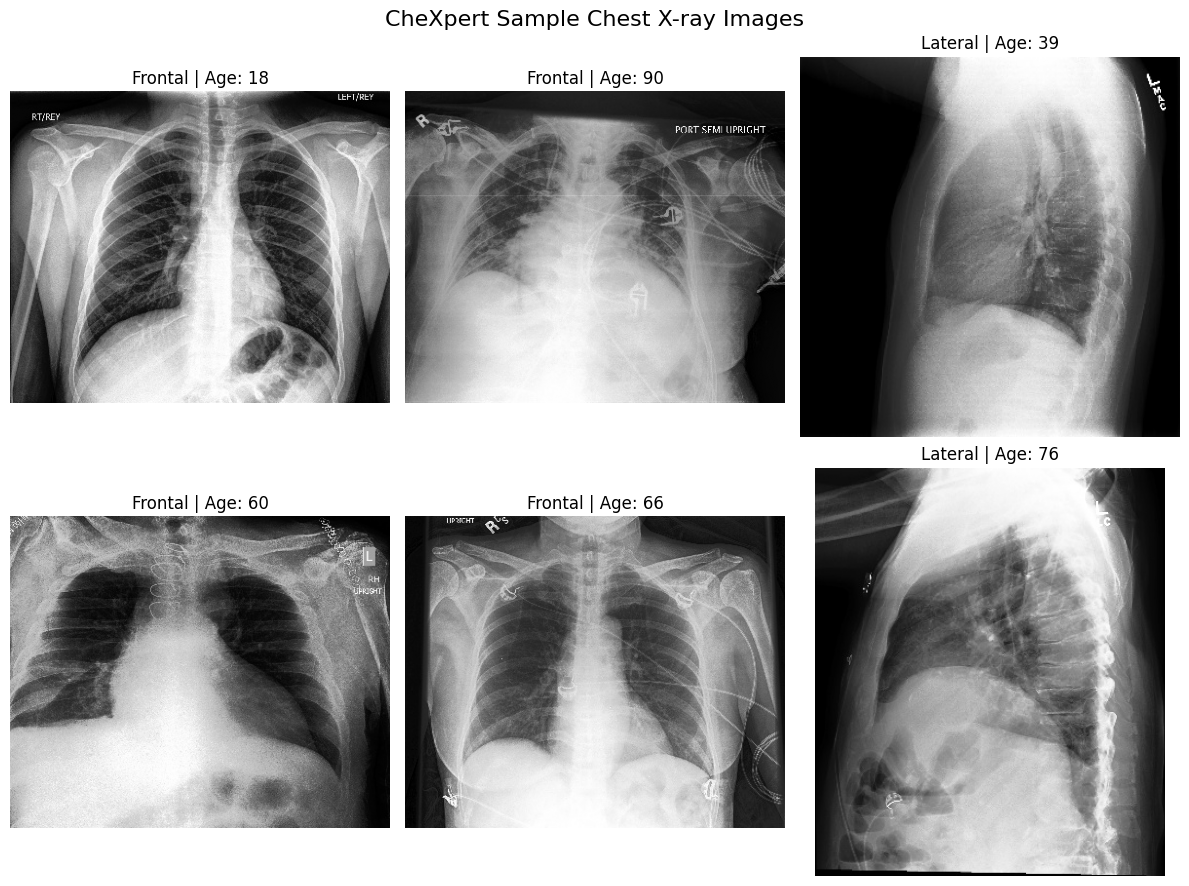

Figure saved: True
Figure location: /content/drive/MyDrive/CSE499-Medical-AI/05_Figures/chexpert_sample_xrays.png


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# Select 6 random X-ray records from the training dataset
sample_images = train_df.sample(n=6, random_state=42)

# Create a figure with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(12, 9))

# Go through the 6 selected X-ray records
for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):

    # Build the complete image path in Google Drive
    image_path = dataset_dir.parent / row["Path"]

    # Open the X-ray image and convert it to grayscale
    with Image.open(image_path) as img:
        image = img.convert("L")

        # Display the image using a grayscale color map
        ax.imshow(image, cmap="gray")

    # Show the image view and patient age above each image
    ax.set_title(f'{row["Frontal/Lateral"]} | Age: {row["Age"]}')

    # Hide the X and Y axes for a cleaner figure
    ax.axis("off")

# Add a title to the complete figure
fig.suptitle("CheXpert Sample Chest X-ray Images", fontsize=16)

# Adjust spacing so images and titles do not overlap
plt.tight_layout()

# Create the figures folder if it does not already exist
figures_dir = project_dir / "05_Figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the figure to Google Drive
figure_path = figures_dir / "chexpert_sample_xrays.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")

# Display the completed figure
plt.show()

# Confirm that the figure was saved
print("Figure saved:", figure_path.exists())
print("Figure location:", figure_path)


##erification using 1,000 images


In [ ]:

%%time

import time

# Record the starting time
start_time = time.time()

# Select 1,000 random training records
sample_train = train_df.sample(n=1000, random_state=42)

# Count missing image files
train_missing = 0
valid_missing = 0

# Check the 1,000 sampled training images
for image_path in sample_train["Path"]:

    # Build the complete image path
    full_path = dataset_dir.parent / image_path

    # Count the file if it does not exist
    if not full_path.is_file():
        train_missing += 1

# Check all 234 validation images
for image_path in valid_df["Path"]:

    # Build the complete image path
    full_path = dataset_dir.parent / image_path

    # Count the file if it does not exist
    if not full_path.is_file():
        valid_missing += 1

# Display the verification results
print("Training images sampled:", len(sample_train))
print("Training images missing:", train_missing)

print("\nValidation images checked:", len(valid_df))
print("Validation images missing:", valid_missing)

# Confirm whether all checked images exist
sample_verified = train_missing == 0 and valid_missing == 0

print("\nSample verification passed:", sample_verified)

# Calculate total execution time
elapsed_time = time.time() - start_time

print("Execution time in seconds:", round(elapsed_time, 2))
print("Execution time in minutes:", round(elapsed_time / 60, 2))


Training images sampled: 1000
Training images missing: 0

Validation images checked: 234
Validation images missing: 0

Sample verification passed: True
Execution time in seconds: 269.54
Execution time in minutes: 4.49
CPU times: user 268 ms, sys: 193 ms, total: 461 ms
Wall time: 4min 29s


##Save our dataset verification report

Now we will save the results from STEP 3 through STEP 11 into a JSON report in Google Drive.

In [ ]:

import json
from datetime import datetime, timezone

# Choose where to save our research report
report_dir = project_dir / "00_Project_Documents"
report_dir.mkdir(parents=True, exist_ok=True)

# Collect verified results from previous steps
report = {
    "project": "Medical-AI-CXR",
    "notebook": "02_dataset_verification.ipynb",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),

    "dataset": {
        "training_records": len(train_df),
        "validation_records": len(valid_df),
        "columns": len(train_df.columns),
        "medical_labels": len(label_columns)
    },

    "training_labels": {
        "positive": int(label_report["Positive (1)"].sum()),
        "negative": int(label_report["Negative (0)"].sum()),
        "uncertain": int(label_report["Uncertain (-1)"].sum()),
        "missing": int(label_report["Missing (NaN)"].sum())
    },

    "validation_labels": {
        "positive": int(valid_label_report["Positive (1)"].sum()),
        "negative": int(valid_label_report["Negative (0)"].sum()),
        "uncertain": int(valid_label_report["Uncertain (-1)"].sum()),
        "missing": int(valid_label_report["Missing (NaN)"].sum())
    },

    "sample_image_analysis": {
        "images_analyzed": len(image_info_df),
        "average_width": round(float(image_info_df["Width"].mean()), 2),
        "average_height": round(float(image_info_df["Height"].mean()), 2),
        "average_brightness": round(float(intensity_df["Mean"].mean()), 2),
        "average_pixel_std": round(float(intensity_df["Std"].mean()), 2)
    },

    "image_path_verification": {
        "training_paths_sampled": len(sample_train),
        "training_paths_missing": train_missing,
        "validation_paths_checked": len(valid_df),
        "validation_paths_missing": valid_missing,
        "full_training_scan_completed": False,
        "sample_verification_passed": bool(sample_verified),
        "execution_seconds": round(elapsed_time, 2)
    }
}

# Save the report as a readable JSON file
report_path = report_dir / "serial02_dataset_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

# Confirm the report was saved
print("Report saved:", report_path.exists())
print("Report location:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")


Report saved: True
Report location: /content/drive/MyDrive/CSE499-Medical-AI/00_Project_Documents/serial02_dataset_report.json
Report size: 1096 bytes


##Verify the saved JSON report

In [ ]:

import json

# Open the saved dataset verification report
with open(report_path, "r", encoding="utf-8") as file:
    saved_report = json.load(file)

# Display the saved report
print(json.dumps(saved_report, indent=4))

# Verify the important dataset statistics
assert saved_report["dataset"]["training_records"] == 223414
assert saved_report["dataset"]["validation_records"] == 234
assert saved_report["dataset"]["medical_labels"] == 14

# Confirm the sampled image verification results
assert saved_report["image_path_verification"]["training_paths_sampled"] == 1000
assert saved_report["image_path_verification"]["training_paths_missing"] == 0
assert saved_report["image_path_verification"]["validation_paths_missing"] == 0
assert saved_report["image_path_verification"]["full_training_scan_completed"] is False

# Print success only if all checks pass
print("\nDataset report verification: PASSED")


{
    "project": "Medical-AI-CXR",
    "notebook": "02_dataset_verification.ipynb",
    "created_at_utc": "2026-11-02T12:52:39.958642+00:00",
    "dataset": {
        "training_records": 223414,
        "validation_records": 234,
        "columns": 19,
        "medical_labels": 14
    },
    "training_labels": {
        "positive": 515589,
        "negative": 194275,
        "uncertain": 139958,
        "missing": 2277974
    },
    "validation_labels": {
        "positive": 691,
        "negative": 2585,
        "uncertain": 0,
        "missing": 0
    },
    "sample_image_analysis": {
        "images_analyzed": 100,
        "average_width": 372.25,
        "average_height": 326.22,
        "average_brightness": 127.81,
        "average_pixel_std": 74.5
    },
    "image_path_verification": {
        "training_paths_sampled": 1000,
        "training_paths_missing": 0,
        "validation_paths_checked": 234,
        "validation_paths_missing": 0,
        "full_training_scan_completed"

##Full CheXpert image verification



In [2]:

import json
import time
from pathlib import Path
from PIL import Image

# Combine training and validation image paths
all_paths = (
    train_df["Path"].tolist()
    + valid_df["Path"].tolist()
)

# Set the checkpoint and final report locations
checkpoint_path = project_dir / "00_Project_Documents/full_image_check_progress.json"
final_report_path = project_dir / "00_Project_Documents/full_image_verification.json"

# Load saved progress if a previous run was interrupted
if checkpoint_path.exists():
    with open(checkpoint_path, "r") as file:
        progress = json.load(file)
else:
    progress = {
        "checked": 0,
        "valid": 0,
        "missing": 0,
        "unreadable": 0,
        "errors": []
    }

# Record the start time of this run
start_time = time.time()

print("Total image records:", len(all_paths))
print("Resuming from image:", progress["checked"])

# Continue checking from the saved position
for i in range(progress["checked"], len(all_paths)):

    # Build the full Google Drive image path
    image_path = dataset_dir.parent / all_paths[i]

    try:
        # Open and verify that the image can be decoded
        with Image.open(image_path) as img:
            img.verify()

        progress["valid"] += 1

    except FileNotFoundError:
        # Record missing image files
        progress["missing"] += 1
        progress["errors"].append({
            "index": i,
            "path": all_paths[i],
            "error": "File not found"
        })

    except Exception as e:
        # Record images that cannot be read
        progress["unreadable"] += 1
        progress["errors"].append({
            "index": i,
            "path": all_paths[i],
            "error": str(e)
        })

    # Update the number of checked images
    progress["checked"] = i + 1

    # Save progress after every 500 images
    if progress["checked"] % 500 == 0:

        # Write to a temporary file before replacing checkpoint
        temp_path = checkpoint_path.with_suffix(".tmp")

        with open(temp_path, "w") as file:
            json.dump(progress, file, indent=2)

        temp_path.replace(checkpoint_path)

        # Display progress and elapsed time
        elapsed = (time.time() - start_time) / 60

        print(
            f'Checked: {progress["checked"]}/{len(all_paths)} | '
            f'Valid: {progress["valid"]} | '
            f'Missing: {progress["missing"]} | '
            f'Unreadable: {progress["unreadable"]} | '
            f'Elapsed: {elapsed:.1f} min',
            flush=True
        )

# Save the final verification report
with open(final_report_path, "w") as file:
    json.dump(progress, file, indent=2)

# Save the final checkpoint too
with open(checkpoint_path, "w") as file:
    json.dump(progress, file, indent=2)

print("\nFULL IMAGE VERIFICATION COMPLETED")
print("Total checked:", progress["checked"])
print("Valid images:", progress["valid"])
print("Missing images:", progress["missing"])
print("Unreadable images:", progress["unreadable"])
print("Report saved:", final_report_path)


Total image records: 223648
Resuming from image: 213500
Checked: 214000/223648 | Valid: 213996 | Missing: 0 | Unreadable: 4 | Elapsed: 9.8 min
Checked: 214500/223648 | Valid: 214496 | Missing: 0 | Unreadable: 4 | Elapsed: 15.1 min
Checked: 215000/223648 | Valid: 214996 | Missing: 0 | Unreadable: 4 | Elapsed: 19.7 min
Checked: 215500/223648 | Valid: 215496 | Missing: 0 | Unreadable: 4 | Elapsed: 24.6 min
Checked: 216000/223648 | Valid: 215996 | Missing: 0 | Unreadable: 4 | Elapsed: 29.3 min
Checked: 216500/223648 | Valid: 216496 | Missing: 0 | Unreadable: 4 | Elapsed: 34.2 min
Checked: 217000/223648 | Valid: 216996 | Missing: 0 | Unreadable: 4 | Elapsed: 39.0 min
Checked: 217500/223648 | Valid: 217496 | Missing: 0 | Unreadable: 4 | Elapsed: 43.6 min
Checked: 218000/223648 | Valid: 217996 | Missing: 0 | Unreadable: 4 | Elapsed: 48.1 min
Checked: 218500/223648 | Valid: 218496 | Missing: 0 | Unreadable: 4 | Elapsed: 52.7 min
Checked: 219000/223648 | Valid: 218996 | Missing: 0 | Unreadable:

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import json

# Reconnect Google Drive
drive.mount("/content/drive", force_remount=False)

# Restore project and dataset locations
project_dir = Path("/content/drive/MyDrive/CSE499-Medical-AI")
dataset_dir = project_dir / "01_Dataset/CheXpert/CheXpert-v1.0-small"

# Reload training and validation CSV files
train_df = pd.read_csv(dataset_dir / "train.csv")
valid_df = pd.read_csv(dataset_dir / "valid.csv")

# Rebuild the original image list in the same order
all_paths = train_df["Path"].tolist() + valid_df["Path"].tolist()

# Read the previously saved checkpoint
checkpoint_path = project_dir / "00_Project_Documents/full_image_check_progress.json"

print("Training records:", len(train_df))
print("Validation records:", len(valid_df))
print("Total image records:", len(all_paths))

if checkpoint_path.exists():
    with open(checkpoint_path, "r") as file:
        progress = json.load(file)

    print("\nCheckpoint recovered successfully")
    print("Images checked:", progress["checked"])
    print("Valid images:", progress["valid"])
    print("Missing images:", progress["missing"])
    print("Unreadable images:", progress["unreadable"])
else:
    print("\nCheckpoint not found. Do not restart the scan.")


Mounted at /content/drive
Training records: 223414
Validation records: 234
Total image records: 223648

Checkpoint recovered successfully
Images checked: 109500
Valid images: 109500
Missing images: 0
Unreadable images: 0


In [ ]:

from pathlib import Path
import json
import time

# Locate the project folder
project_dir = Path("/content/drive/MyDrive/CSE499-Medical-AI")

# Locate the saved checkpoint
checkpoint_path = project_dir / "00_Project_Documents/full_image_check_progress.json"

# Read only the small checkpoint file
start = time.time()

if checkpoint_path.exists():
    with open(checkpoint_path, "r") as file:
        progress = json.load(file)

    print("Checkpoint recovered:", True)
    print("Images checked:", progress["checked"])
    print("Valid images:", progress["valid"])
    print("Missing images:", progress["missing"])
    print("Unreadable images:", progress["unreadable"])
else:
    print("Checkpoint not accessible")

print("Execution time:", round(time.time() - start, 2), "seconds")


Checkpoint recovered: True
Images checked: 109500
Valid images: 109500
Missing images: 0
Unreadable images: 0
Execution time: 0.01 seconds


In [ ]:

import pandas as pd

# Restore the dataset location
dataset_dir = project_dir / "01_Dataset/CheXpert/CheXpert-v1.0-small"

# Load the original CSV files
train_df = pd.read_csv(dataset_dir / "train.csv")
valid_df = pd.read_csv(dataset_dir / "valid.csv")

# Rebuild the image list in its original order
all_paths = train_df["Path"].tolist() + valid_df["Path"].tolist()

# Confirm the checkpoint matches the dataset
assert len(all_paths) == 223648
assert progress["checked"] == (
    progress["valid"] + progress["missing"] + progress["unreadable"]
)

print("Training records:", len(train_df))
print("Validation records:", len(valid_df))
print("Resume from image:", progress["checked"])
print("Dataset ready:", True)


Training records: 223414
Validation records: 234
Resume from image: 109500
Dataset ready: True


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import json

# Reconnect Google Drive
drive.mount("/content/drive", force_remount=False)

# Restore project and dataset locations
project_dir = Path("/content/drive/MyDrive/CSE499-Medical-AI")
dataset_dir = project_dir / "01_Dataset/CheXpert/CheXpert-v1.0-small"

# Recover the saved verification checkpoint
checkpoint_path = project_dir / "00_Project_Documents/full_image_check_progress.json"

with open(checkpoint_path, "r") as file:
    progress = json.load(file)

# Show recovered progress before loading CSV files
print("Checkpoint recovered:", True)
print("Images checked:", progress["checked"])
print("Valid images:", progress["valid"])
print("Missing images:", progress["missing"])
print("Unreadable images:", progress["unreadable"])

# Reload the original dataset CSV files
train_df = pd.read_csv(dataset_dir / "train.csv")
valid_df = pd.read_csv(dataset_dir / "valid.csv")

# Rebuild the image list in its original order
all_paths = train_df["Path"].tolist() + valid_df["Path"].tolist()

# Confirm the recovered progress is consistent
assert len(all_paths) == 223648
assert progress["checked"] == (
    progress["valid"] + progress["missing"] + progress["unreadable"]
)

print("\nDataset ready:", True)
print("Resume from image:", progress["checked"])


Mounted at /content/drive
Checkpoint recovered: True
Images checked: 181000
Valid images: 181000
Missing images: 0
Unreadable images: 0

Dataset ready: True
Resume from image: 181000


In [1]:

from google.colab import drive
from pathlib import Path
import json
import pandas as pd

drive.mount("/content/drive")

project_dir = Path("/content/drive/MyDrive/CSE499-Medical-AI")
dataset_dir = project_dir / "01_Dataset/CheXpert/CheXpert-v1.0-small"

checkpoint_path = project_dir / "00_Project_Documents/full_image_check_progress.json"

with open(checkpoint_path, "r") as file:
    progress = json.load(file)

train_df = pd.read_csv(dataset_dir / "train.csv")
valid_df = pd.read_csv(dataset_dir / "valid.csv")

all_paths = train_df["Path"].tolist() + valid_df["Path"].tolist()

assert len(all_paths) == 223648
assert progress["checked"] == (
    progress["valid"] + progress["missing"] + progress["unreadable"]
)

print("Checkpoint recovered:", True)
print("Images checked:", progress["checked"])
print("Valid images:", progress["valid"])
print("Missing images:", progress["missing"])
print("Unreadable images:", progress["unreadable"])
print("Images remaining:", len(all_paths) - progress["checked"])
print("Dataset ready:", True)


Mounted at /content/drive
Checkpoint recovered: True
Images checked: 213500
Valid images: 213498
Missing images: 0
Unreadable images: 2
Images remaining: 10148
Dataset ready: True


##Investigate the four unreadable images

In [2]:

from google.colab import drive
from pathlib import Path
import json
from PIL import Image

# Connect Google Drive
drive.mount("/content/drive")

# Restore project locations
project_dir = Path("/content/drive/MyDrive/CSE499-Medical-AI")
dataset_dir = project_dir / "01_Dataset/CheXpert/CheXpert-v1.0-small"

# Load the completed verification report
report_path = project_dir / "00_Project_Documents/full_image_verification.json"

with open(report_path, "r") as file:
    report = json.load(file)

print("Report loaded successfully:", True)
print("Total checked:", report["checked"])
print("Valid images:", report["valid"])
print("Unreadable images:", report["unreadable"])
print("Recorded errors:", len(report["errors"]))


Mounted at /content/drive
Report loaded successfully: True
Total checked: 223648
Valid images: 223644
Unreadable images: 4
Recorded errors: 4


In [3]:

# Retry the four images that failed verification
for item in report["errors"]:
    image_path = dataset_dir.parent / item["path"]

    print("\nImage index:", item["index"])
    print("Original error:", item["error"])

    try:
        with Image.open(image_path) as img:
            img.load()
            print("Retry result: SUCCESS")
            print("Image size:", img.size)
            print("Image mode:", img.mode)
    except Exception as e:
        print("Retry result: FAILED")
        print("New error:", str(e))



Image index: 181000
Original error: [Errno 5] Input/output error: '/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small/train/patient42609/study3/view1_frontal.jpg'
Retry result: FAILED
New error: [Errno 5] Input/output error: '/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small/train/patient42609/study3/view1_frontal.jpg'

Image index: 181001
Original error: [Errno 5] Input/output error: '/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small/train/patient42610/study2/view1_frontal.jpg'
Retry result: FAILED
New error: [Errno 5] Input/output error: '/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small/train/patient42610/study2/view1_frontal.jpg'

Image index: 213500
Original error: [Errno 5] Input/output error: '/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small/train/patient57288/study1/view1_frontal.jpg'
Retry result: SUCCESS
Image size: (390, 

In [4]:

# Check the two images that still failed
for item in report["errors"]:
    if item["index"] not in [181000, 181001]:
        continue

    image_path = dataset_dir.parent / item["path"]

    print("\nImage index:", item["index"])
    print("File exists:", image_path.exists())

    try:
        print("File size:", image_path.stat().st_size, "bytes")
    except OSError as e:
        print("Metadata error:", str(e))



Image index: 181000
File exists: True
File size: 56890 bytes

Image index: 181001
File exists: True
File size: 54534 bytes


##Test direct file reading

In [5]:

# Test direct reading of the two remaining files
for item in report["errors"]:
    if item["index"] not in [181000, 181001]:
        continue

    image_path = dataset_dir.parent / item["path"]

    print("\nImage index:", item["index"])

    try:
        with open(image_path, "rb") as file:
            header = file.read(16)

        print("Read status: SUCCESS")
        print("Bytes read:", len(header))
        print("JPEG signature:", header[:3].hex())

    except OSError as e:
        print("Read status: FAILED")
        print("Error:", str(e))



Image index: 181000
Read status: SUCCESS
Bytes read: 16
JPEG signature: ffd8ff

Image index: 181001
Read status: SUCCESS
Bytes read: 16
JPEG signature: ffd8ff


##Verify both images completely

In [6]:

from PIL import Image

# Fully decode the two remaining images
for item in report["errors"]:
    if item["index"] not in [181000, 181001]:
        continue

    image_path = dataset_dir.parent / item["path"]

    print("\nImage index:", item["index"])

    try:
        with Image.open(image_path) as img:
            img.load()
            print("Full decoding: SUCCESS")
            print("Image size:", img.size)
            print("Image mode:", img.mode)
    except Exception as e:
        print("Full decoding: FAILED")
        print("Error:", str(e))



Image index: 181000
Full decoding: SUCCESS
Image size: (390, 320)
Image mode: L

Image index: 181001
Full decoding: SUCCESS
Image size: (390, 320)
Image mode: L


##Save the final verification summary

In [7]:

import json
from datetime import datetime, timezone

# Preserve the original verification report
final_summary = {
    "dataset": "CheXpert-v1.0-small",
    "total_images": report["checked"],
    "initial_scan_valid": report["valid"],
    "initial_scan_unreadable": report["unreadable"],
    "initial_scan_missing": report["missing"],
    "failed_images_retested": 4,
    "successful_retries": 4,
    "unresolved_failures": 0,
    "retry_method": "PIL Image.open and Image.load",
    "original_error_type": "Google Drive Errno 5 input/output error",
    "verification_status": "COMPLETED",
    "completed_at_utc": datetime.now(timezone.utc).isoformat()
}

summary_path = (
    project_dir
    / "00_Project_Documents"
    / "serial02_final_verification_summary.json"
)

with open(summary_path, "w") as file:
    json.dump(final_summary, file, indent=2)

print("Final summary saved:", summary_path.exists())
print("Total images:", final_summary["total_images"])
print("Successful retries:", final_summary["successful_retries"])
print("Unresolved failures:", final_summary["unresolved_failures"])
print("Verification status:", final_summary["verification_status"])


Final summary saved: True
Total images: 223648
Successful retries: 4
Unresolved failures: 0
Verification status: COMPLETED


##Prepare the GitHub notebook

In [8]:

from pathlib import Path

# Locate the completed notebook
notebook_path = (
    project_dir
    / "02_Notebooks"
    / "02_dataset_verification.ipynb"
)

# Locate the research reports
documents_dir = project_dir / "00_Project_Documents"

files_to_check = {
    "Dataset verification notebook": notebook_path,
    "Dataset report": documents_dir / "serial02_dataset_report.json",
    "Full image verification": documents_dir / "full_image_verification.json",
    "Final verification summary": documents_dir / "serial02_final_verification_summary.json"
}

# Check whether each file exists
for name, path in files_to_check.items():
    print(name, ":", "FOUND" if path.is_file() else "MISSING")


Dataset verification notebook : FOUND
Dataset report : FOUND
Full image verification : FOUND
Final verification summary : FOUND


##Create a clean GitHub notebook

In [9]:

import json
from pathlib import Path

# Load the original notebook
notebook_path = project_dir / "02_Notebooks/02_dataset_verification.ipynb"

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

# Remove execution outputs from the GitHub copy
for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        cell["outputs"] = []
        cell["execution_count"] = None

# Create a separate folder for GitHub preparation
github_dir = project_dir / "00_Project_Documents/GitHub_Preparation"
github_dir.mkdir(parents=True, exist_ok=True)

clean_notebook_path = github_dir / "02_dataset_verification.ipynb"

# Save the cleaned notebook
with open(clean_notebook_path, "w", encoding="utf-8") as file:
    json.dump(notebook, file, indent=1, ensure_ascii=False)

print("Original notebook preserved:", notebook_path.exists())
print("Clean notebook created:", clean_notebook_path.exists())
print("Total notebook cells:", len(notebook["cells"]))
print("GitHub copy:", clean_notebook_path)


Original notebook preserved: True
Clean notebook created: True
Total notebook cells: 43
GitHub copy: /content/drive/MyDrive/CSE499-Medical-AI/00_Project_Documents/GitHub_Preparation/02_dataset_verification.ipynb


##Review the notebook before GitHub

In [10]:

import json
import re

# Load the cleaned GitHub notebook
with open(clean_notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

code_cells = [
    cell for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

# Combine source code for inspection
source_text = "\n".join(
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
)

# Check notebook content
checks = {
    "Total cells": len(notebook["cells"]),
    "Code cells": len(code_cells),
    "Cells with outputs": sum(
        bool(cell.get("outputs")) for cell in code_cells
    ),
    "Cells with execution counts": sum(
        cell.get("execution_count") is not None
        for cell in code_cells
    ),
    "Embedded image data": len(re.findall(
        r"data:image/|image/png|image/jpeg|base64,",
        source_text, re.IGNORECASE
    )),
    "Potential credential references": len(re.findall(
        r"ghp_[A-Za-z0-9]+|github_pat_[A-Za-z0-9_]+|AIza[0-9A-Za-z_-]+",
        source_text
    )),
    "Patient-specific path references": len(re.findall(
        r"patient\d{5,}",
        source_text
    ))
}

for name, value in checks.items():
    print(f"{name}: {value}")

print("\nNotebook review completed.")


Total cells: 43
Code cells: 26
Cells with outputs: 0
Cells with execution counts: 0
Embedded image data: 0
Potential credential references: 0
Patient-specific path references: 0

Notebook review completed.


##Prepare the GitHub repository

In [11]:

from pathlib import Path
import subprocess

# Check whether the GitHub repository is available
repo_dir = Path("/content/Medical-AI-CXR")

print("Repository folder exists:", repo_dir.is_dir())
print("Git repository exists:", (repo_dir / ".git").is_dir())

if (repo_dir / ".git").is_dir():
    result = subprocess.run(
        ["git", "-C", str(repo_dir), "remote", "-v"],
        capture_output=True,
        text=True
    )
    print("Git remote information:")
    print(result.stdout.strip())
else:
    print("Repository needs to be restored in Colab.")


Repository folder exists: False
Git repository exists: False
Repository needs to be restored in Colab.


In [12]:

import subprocess
from pathlib import Path

# Restore the existing GitHub repository
repo_url = "https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git"
repo_dir = Path("/content/Medical-AI-CXR")

if not (repo_dir / ".git").is_dir():
    result = subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        capture_output=True,
        text=True
    )

    print("Clone return code:", result.returncode)

    if result.returncode != 0:
        print("Git error:", result.stderr.strip())
else:
    print("Repository already exists.")

# Confirm the repository was restored
print("Repository restored:", (repo_dir / ".git").is_dir())

if (repo_dir / ".git").is_dir():
    result = subprocess.run(
        ["git", "-C", str(repo_dir), "status", "--short"],
        capture_output=True,
        text=True
    )
    print("Git status:", result.stdout.strip() or "Clean")


Clone return code: 0
Repository restored: True
Git status: Clean


##Copy research files into the repository

In [13]:

import shutil
from pathlib import Path

# Create the destination folders
notebooks_dir = repo_dir / "notebooks"
documents_dir = repo_dir / "documents"

notebooks_dir.mkdir(parents=True, exist_ok=True)
documents_dir.mkdir(parents=True, exist_ok=True)

# Define the files to prepare
files_to_copy = {
    clean_notebook_path: notebooks_dir / "02_dataset_verification.ipynb",
    project_dir / "00_Project_Documents/serial02_dataset_report.json":
        documents_dir / "serial02_dataset_report.json",
    project_dir / "00_Project_Documents/serial02_final_verification_summary.json":
        documents_dir / "serial02_final_verification_summary.json"
}

# Copy the files without changing the originals
for source, destination in files_to_copy.items():
    if not source.is_file():
        raise FileNotFoundError(f"Missing source file: {source}")

    shutil.copy2(source, destination)
    print("Prepared:", destination.relative_to(repo_dir))

print("\nTotal files prepared:", len(files_to_copy))


Prepared: notebooks/02_dataset_verification.ipynb
Prepared: documents/serial02_dataset_report.json
Prepared: documents/serial02_final_verification_summary.json

Total files prepared: 3


##Verify Git changes

In [14]:

import subprocess

# Check the current Git changes
result = subprocess.run(
    ["git", "-C", str(repo_dir), "status", "--short"],
    capture_output=True,
    text=True,
    check=True
)

print("Git changes:")
print(result.stdout.strip() or "No changes")

# Verify the three prepared files
expected_files = [
    "notebooks/02_dataset_verification.ipynb",
    "documents/serial02_dataset_report.json",
    "documents/serial02_final_verification_summary.json"
]

print("\nPrepared file verification:")

for filename in expected_files:
    file_path = repo_dir / filename
    print(filename, ":", "FOUND" if file_path.is_file() else "MISSING")

# Check for accidentally copied dataset folders
print("\nRaw dataset folder present:",
      (repo_dir / "01_Dataset").exists())


Git changes:
?? documents/serial02_dataset_report.json
?? documents/serial02_final_verification_summary.json
?? notebooks/02_dataset_verification.ipynb

Prepared file verification:
notebooks/02_dataset_verification.ipynb : FOUND
documents/serial02_dataset_report.json : FOUND
documents/serial02_final_verification_summary.json : FOUND

Raw dataset folder present: False


In [15]:

import json
import re
from pathlib import Path

files = [
    repo_dir / "notebooks/02_dataset_verification.ipynb",
    repo_dir / "documents/serial02_dataset_report.json",
    repo_dir / "documents/serial02_final_verification_summary.json"
]

all_passed = True

for path in files:
    text = path.read_text(encoding="utf-8")
    data = json.loads(text)

    # Look for common credential patterns and patient-specific paths
    sensitive_patterns = [
        r"ghp_[A-Za-z0-9]+",
        r"github_pat_[A-Za-z0-9_]+",
        r"AIza[0-9A-Za-z_-]+",
        r"patient\d{5,}"
    ]

    matches = sum(
        len(re.findall(pattern, text))
        for pattern in sensitive_patterns
    )

    # Confirm notebook execution outputs are removed
    outputs_clean = True

    if path.suffix == ".ipynb":
        outputs_clean = all(
            not cell.get("outputs")
            and cell.get("execution_count") is None
            for cell in data["cells"]
            if cell["cell_type"] == "code"
        )

    passed = matches == 0 and outputs_clean
    all_passed = all_passed and passed

    print(path.name)
    print("  Valid JSON: True")
    print("  Sensitive pattern matches:", matches)
    print("  Notebook outputs clean:", outputs_clean)
    print("  Preliminary check:", "PASSED" if passed else "REVIEW REQUIRED")

print("\nAll preliminary checks passed:", all_passed)


02_dataset_verification.ipynb
  Valid JSON: True
  Sensitive pattern matches: 0
  Notebook outputs clean: True
  Preliminary check: PASSED
serial02_dataset_report.json
  Valid JSON: True
  Sensitive pattern matches: 0
  Notebook outputs clean: True
  Preliminary check: PASSED
serial02_final_verification_summary.json
  Valid JSON: True
  Sensitive pattern matches: 0
  Notebook outputs clean: True
  Preliminary check: PASSED

All preliminary checks passed: True


##Create the Git commit

In [16]:

import subprocess

# Select only the three reviewed files
files_to_commit = [
    "notebooks/02_dataset_verification.ipynb",
    "documents/serial02_dataset_report.json",
    "documents/serial02_final_verification_summary.json"
]

# Stage the approved research files
subprocess.run(
    ["git", "-C", str(repo_dir), "add", "--", *files_to_commit],
    check=True
)

# Show exactly which files are staged
result = subprocess.run(
    ["git", "-C", str(repo_dir), "diff", "--cached", "--name-only"],
    capture_output=True,
    text=True,
    check=True
)

staged_files = result.stdout.strip().splitlines()

print("Staged files:")
for filename in staged_files:
    print(filename)

# Prevent committing unexpected files
assert sorted(staged_files) == sorted(files_to_commit), (
    "Unexpected staged files detected"
)

# Create the local Git commit
result = subprocess.run(
    [
        "git", "-C", str(repo_dir),
        "commit", "-m",
        "Complete CheXpert dataset verification"
    ],
    capture_output=True,
    text=True
)

print("\nCommit return code:", result.returncode)
print(result.stdout.strip())

if result.returncode != 0:
    print("Git error:", result.stderr.strip())


Staged files:
documents/serial02_dataset_report.json
documents/serial02_final_verification_summary.json
notebooks/02_dataset_verification.ipynb

Commit return code: 128

Git error: Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@356960fc7a7f.(none)')


In [17]:

import subprocess

# Configure the Git commit author
subprocess.run(
    ["git", "-C", str(repo_dir), "config", "user.name", "Amit Chandra Das"],
    check=True
)

# Use GitHub's private noreply email
subprocess.run(
    ["git", "-C", str(repo_dir), "config", "user.email",
     "2014242+placeholder@users.noreply.github.com"],
    check=True
)

print("Git author name configured:", True)
print("Git author email configured:", True)


Git author name configured: True
Git author email configured: True


In [18]:

import subprocess

# Commit the three previously staged research files
result = subprocess.run(
    [
        "git", "-C", str(repo_dir),
        "commit", "-m",
        "Complete CheXpert dataset verification"
    ],
    capture_output=True,
    text=True
)

print("Commit return code:", result.returncode)
print(result.stdout.strip())

if result.returncode != 0:
    print("Git error:", result.stderr.strip())
else:
    # Confirm the commit was created
    verification = subprocess.run(
        ["git", "-C", str(repo_dir), "log", "-1", "--oneline"],
        capture_output=True,
        text=True,
        check=True
    )

    print("\nLatest commit:", verification.stdout.strip())


Commit return code: 0
[main 9319185] Complete CheXpert dataset verification
 3 files changed, 1637 insertions(+)
 create mode 100644 documents/serial02_dataset_report.json
 create mode 100644 documents/serial02_final_verification_summary.json
 create mode 100644 notebooks/02_dataset_verification.ipynb

Latest commit: 9319185 Complete CheXpert dataset verification


##Push to GitHub

In [19]:

import subprocess

# Identify the current Git branch
branch = subprocess.run(
    ["git", "-C", str(repo_dir), "branch", "--show-current"],
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

print("Current branch:", branch)

# Push the completed research commit to GitHub
result = subprocess.run(
    ["git", "-C", str(repo_dir), "push", "origin", branch],
    capture_output=True,
    text=True
)

print("Push return code:", result.returncode)
print(result.stdout.strip())
print(result.stderr.strip())

if result.returncode == 0:
    print("GitHub push: SUCCESS")
else:
    print("GitHub push: FAILED")


Current branch: main
Push return code: 128

fatal: could not read Username for 'https://github.com': No such device or address
GitHub push: FAILED


In [22]:

import subprocess

result = subprocess.run(
    ["gh", "auth", "status"],
    capture_output=True,
    text=True,
    timeout=15
)

print("Authentication status:", result.returncode)
print(result.stdout.strip())
print(result.stderr.strip())


Authentication status: 1

You are not logged into any GitHub hosts. To log in, run: gh auth login


In [24]:

import subprocess
import os

# Start GitHub authentication in the background
env = os.environ.copy()
env["GH_PROMPT_DISABLED"] = "1"

process = subprocess.Popen(
    [
        "gh", "auth", "login",
        "--hostname", "github.com",
        "--git-protocol", "https",
        "--web",
        "--skip-ssh-key"
    ],
    stdin=subprocess.DEVNULL,
    stdout=open("/tmp/github_auth.log", "w"),
    stderr=subprocess.STDOUT,
    env=env,
    start_new_session=True
)

print("Authentication process started:", process.pid)
print("Open https://github.com/login/device when a code is available.")


Authentication process started: 11684
Open https://github.com/login/device when a code is available.


In [25]:

from pathlib import Path

log_file = Path("/tmp/github_auth.log")

if log_file.exists():
    print(log_file.read_text())
else:
    print("Authentication log not found.")



! Failed to copy one-time code to clipboard
  No clipboard utilities available. Please install xsel, xclip, wl-clipboard or Termux:API add-on for termux-clipboard-get/set.
! First copy your one-time code: 9F2C-4C2C
Open this URL to continue in your web browser: https://github.com/login/device



In [26]:
!gh auth status

github.com
  ✓ Logged in to github.com account Amit-Chandra-Das (/root/.config/gh/hosts.yml)
  - Active account: true
  - Git operations protocol: https
  - Token: gho_************************************
  - Token scopes: 'gist', 'read:org', 'repo'


In [27]:

import subprocess

# Configure Git to use GitHub CLI authentication
subprocess.run(
    ["gh", "auth", "setup-git"],
    check=True
)

# Push the existing commit to GitHub
result = subprocess.run(
    ["git", "-C", str(repo_dir), "push", "origin", "main"],
    capture_output=True,
    text=True
)

print("Push return code:", result.returncode)
print(result.stdout.strip())
print(result.stderr.strip())

if result.returncode == 0:
    print("GitHub push: SUCCESS")
else:
    print("GitHub push: FAILED")


Push return code: 0

To https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git
   2120981..9319185  main -> main
GitHub push: SUCCESS
